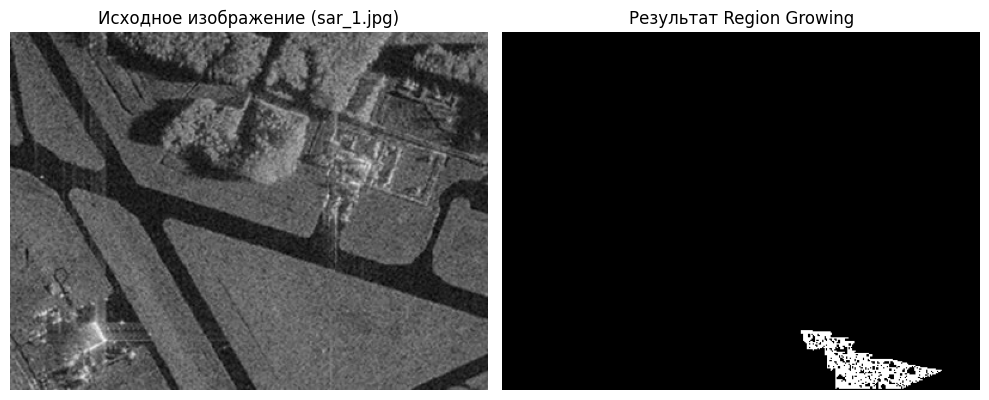

In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

image_sar = cv2.imread('sar_1.jpg', cv2.IMREAD_GRAYSCALE)

def homo_average(img, mask, point, T):
    av_val = img[mask > 0].sum() / np.count_nonzero(mask > 0)
    return abs(float(av_val) - float(img[point])) <= T

def region_growing(image, seed_point, homo_fun, r, T):
    mask = np.zeros(image.shape, dtype=np.uint8)
    mask[seed_point] = 1
    count = 1
    while count > 0:
        local_mask = np.zeros(image.shape, dtype=np.uint8)
        for i in range(r, image.shape[0] - r):
            for j in range(r, image.shape[1] - r):
                if mask[i, j] == 0 and mask[i - r:i + r, j - r:j + r].sum() > 0:
                    if homo_fun(image, mask, (i, j), T):
                        local_mask[i, j] = 1
        count = np.count_nonzero(local_mask)
        mask += local_mask
    return mask * 255

seed_point = (250, 250)
mask_grown = region_growing(image_sar, seed_point, homo_average, 1, 10)

plt.figure(figsize=(10, 5))
plt.subplot(1, 2, 1)
plt.imshow(image_sar, cmap='gray')
plt.title('Исходное изображение (sar_1.jpg)')
plt.axis('off')

plt.subplot(1, 2, 2)
plt.imshow(mask_grown, cmap='gray')
plt.title('Результат Region Growing')
plt.axis('off')
plt.tight_layout()
plt.show()

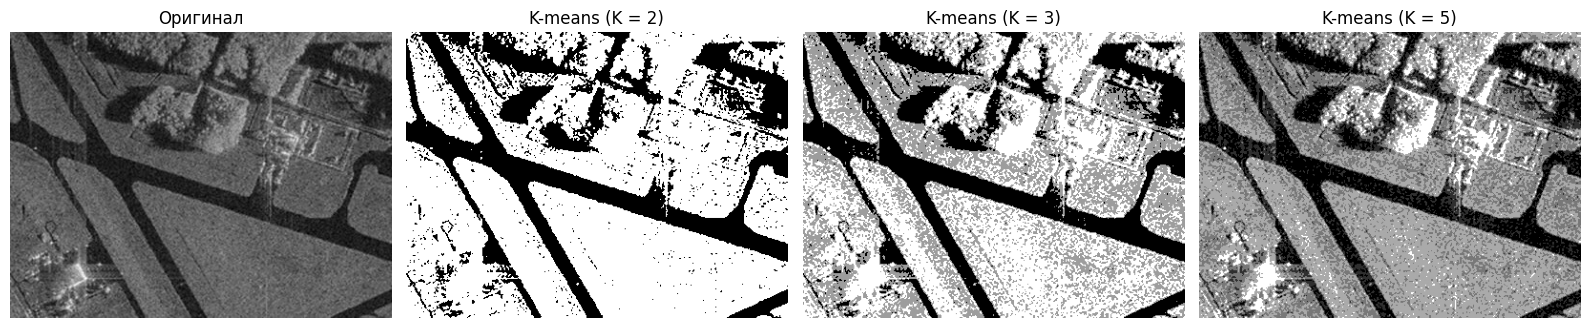

In [2]:
image_sar_color = cv2.imread('sar_1.jpg')
image_sar_gray = cv2.cvtColor(image_sar_color, cv2.COLOR_BGR2GRAY)

z = image_sar_gray.reshape((-1, 1)).astype(np.float32)
criteria = (cv2.TERM_CRITERIA_EPS + cv2.TERM_CRITERIA_MAX_ITER, 10, 1.0)
flags = cv2.KMEANS_RANDOM_CENTERS

k_values = [2, 3, 5]
segmented_images = []

for k in k_values:
    compactness, labels, centers = cv2.kmeans(z, k, None, criteria, 10, flags)
    centers = np.uint8(centers)
    res = centers[labels.flatten()]
    res_img = res.reshape(image_sar_gray.shape)
    segmented_images.append(res_img)

plt.figure(figsize=(16, 4))
plt.subplot(1, 4, 1)
plt.imshow(image_sar_gray, cmap='gray')
plt.title('Оригинал')
plt.axis('off')

for idx, (k, img_k) in enumerate(zip(k_values, segmented_images)):
    plt.subplot(1, 4, idx + 2)
    plt.imshow(img_k, cmap='gray')
    plt.title(f'K-means (K = {k})')
    plt.axis('off')

plt.tight_layout()
plt.show()

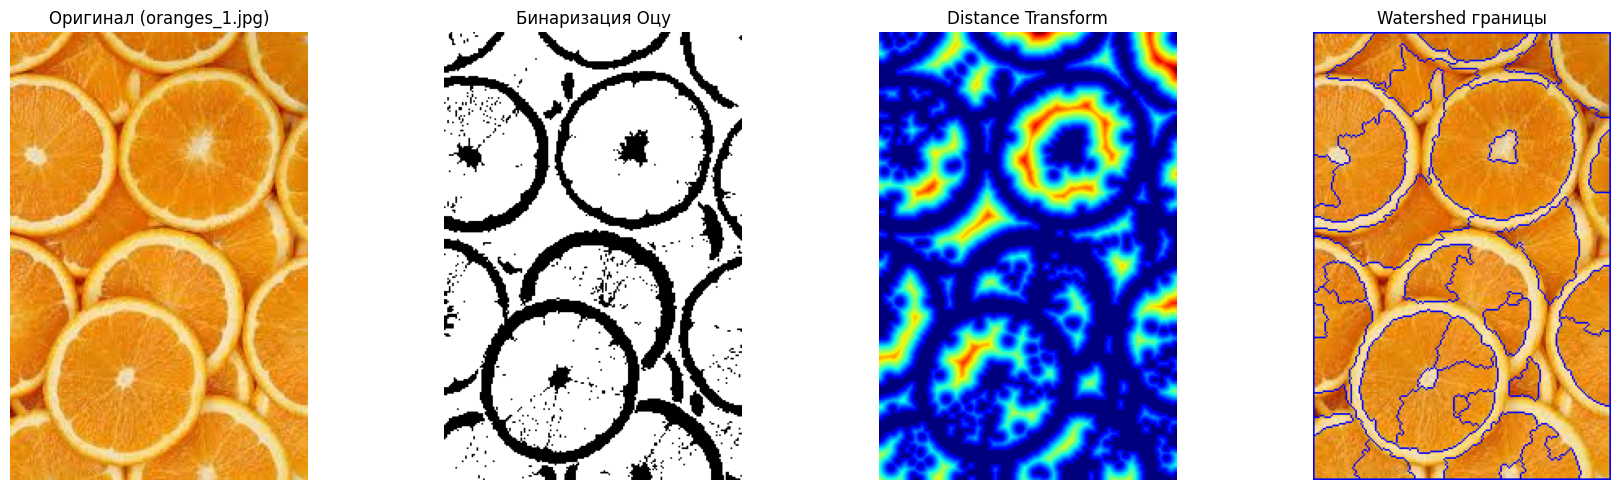

In [3]:
image_oranges = cv2.imread('oranges_1.jpg')
gray_oranges = cv2.cvtColor(image_oranges, cv2.COLOR_BGR2GRAY)

_, thresh = cv2.threshold(gray_oranges, 0, 255, cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU)

kernel = np.ones((3, 3), np.uint8)
opening = cv2.morphologyEx(thresh, cv2.MORPH_OPEN, kernel, iterations=2)

sure_bg = cv2.dilate(opening, kernel, iterations=3)

dist_transform = cv2.distanceTransform(opening, cv2.DIST_L2, 5)
_, sure_fg = cv2.threshold(dist_transform, 0.5 * dist_transform.max(), 255, 0)
sure_fg = np.uint8(sure_fg)

unknown = cv2.subtract(sure_bg, sure_fg)

_, markers = cv2.connectedComponents(sure_fg)
markers = markers + 1
markers[unknown == 255] = 0

markers = cv2.watershed(image_oranges, markers)

result_watershed = image_oranges.copy()
result_watershed[markers == -1] = [255, 0, 0]

plt.figure(figsize=(18, 5))

plt.subplot(1, 4, 1)
plt.imshow(cv2.cvtColor(image_oranges, cv2.COLOR_BGR2RGB))
plt.title('Оригинал (oranges_1.jpg)')
plt.axis('off')

plt.subplot(1, 4, 2)
plt.imshow(thresh, cmap='gray')
plt.title('Бинаризация Оцу')
plt.axis('off')

plt.subplot(1, 4, 3)
plt.imshow(dist_transform, cmap='jet')
plt.title('Distance Transform')
plt.axis('off')

plt.subplot(1, 4, 4)
plt.imshow(cv2.cvtColor(result_watershed, cv2.COLOR_BGR2RGB))
plt.title('Watershed границы')
plt.axis('off')

plt.tight_layout()
plt.show()